In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
configs_csv = "interactive_chart_configuration_matrix.csv"
if not os.path.exists(configs_csv):
    configs_csv = os.path.join("03-11-2026", "Task 3", "interactive_chart_configuration_matrix.csv")

df_configs = pd.read_csv(configs_csv)
print(f"Loaded Interactive Chart Configuration Specifications: {len(df_configs)} chart archetypes.")
display(df_configs[['Chart_Type', 'Primary_Engine', 'X_Dimension', 'Y_Dimension', 'Color_Dimension']])

Loaded Interactive Chart Configuration Specifications: 6 chart archetypes.


,Chart_Type,Primary_Engine,X_Dimension,Y_Dimension,Color_Dimension
0,Categorical Bar Chart,Plotly (px.bar),Department Name / Class Name,Record Count / Mean Rating,Recommended IND (Binary)
1,Continuous Scatter Plot,Plotly (px.scatter),Age (Customer Demographics),Positive Feedback Count,Rating (1 to 5 Stars)
2,Distribution Box Plot,Plotly (px.box),Department Name,Rating / Customer Age,Department Name
3,Proportional Donut Chart,Plotly (px.pie with hole=0.5),N/A (Sectors),Aggregate Review Volume,Department Name
4,Density Histogram,Plotly (px.histogram),Customer Age (Binned),Review Count (Frequency),Recommended IND
5,Correlation Heatmap,Plotly (px.imshow),Department Name,Rating Scale (1 to 5),Relative Review Frequency


In [3]:
themes_csv = "color_palette_and_theme_specifications.csv"
if not os.path.exists(themes_csv):
    themes_csv = os.path.join("03-11-2026", "Task 3", "color_palette_and_theme_specifications.csv")

df_themes = pd.read_csv(themes_csv)
display(df_themes)

,Theme_Name,Primary_Hex,Secondary_Hex,Accent_Hex,Background_Hex,Text_Hex,Contrast_Ratio
0,Deep Navy (Default),#1A365D,#2B6CB0,#319795,#FFFFFF,#2D3748,12.4:1 (WCAG AAA)
1,Emerald Teal,#22543D,#2F855A,#38B2AC,#F7FAFC,#1A202C,11.8:1 (WCAG AAA)
2,Sunset Coral,#7B341E,#DD6B20,#E53E3E,#FFF5F5,#2D3748,9.6:1 (WCAG AAA)
3,Viridis Scientific,#440154,#31688E,#35B779,#FAFAFA,#1A202C,14.1:1 (WCAG AAA)
4,Plasma Warm,#0D0887,#7E03A8,#F89540,#FFFFFF,#2D3748,13.2:1 (WCAG AAA)


In [4]:
latency_csv = "visualization_rendering_latency_benchmarks.csv"
if not os.path.exists(latency_csv):
    latency_csv = os.path.join("03-11-2026", "Task 3", "visualization_rendering_latency_benchmarks.csv")

df_latency = pd.read_csv(latency_csv)
display(df_latency)

,Chart_Type,Dataset_Rows,Plotly_Latency_ms,Altair_Latency_ms,Memory_Overhead_KB,FPS_Performance
0,Categorical Bar Chart,1000,12.4,18.2,142.0,60 FPS (Fluid)
1,Categorical Bar Chart,5000,18.6,29.4,310.0,60 FPS (Fluid)
2,Categorical Bar Chart,23486,28.2,48.5,840.0,60 FPS (Fluid)
3,Continuous Scatter Plot,1000,14.8,22.1,210.0,60 FPS (Fluid)
4,Continuous Scatter Plot,5000,32.5,54.8,620.0,55 FPS (Smooth)
5,Continuous Scatter Plot,23486,64.2,118.6,1850.0,48 FPS (Acceptable)
6,Distribution Box Plot,23486,22.4,36.8,480.0,60 FPS (Fluid)
7,Proportional Donut Chart,23486,11.2,16.5,95.0,60 FPS (Fluid)


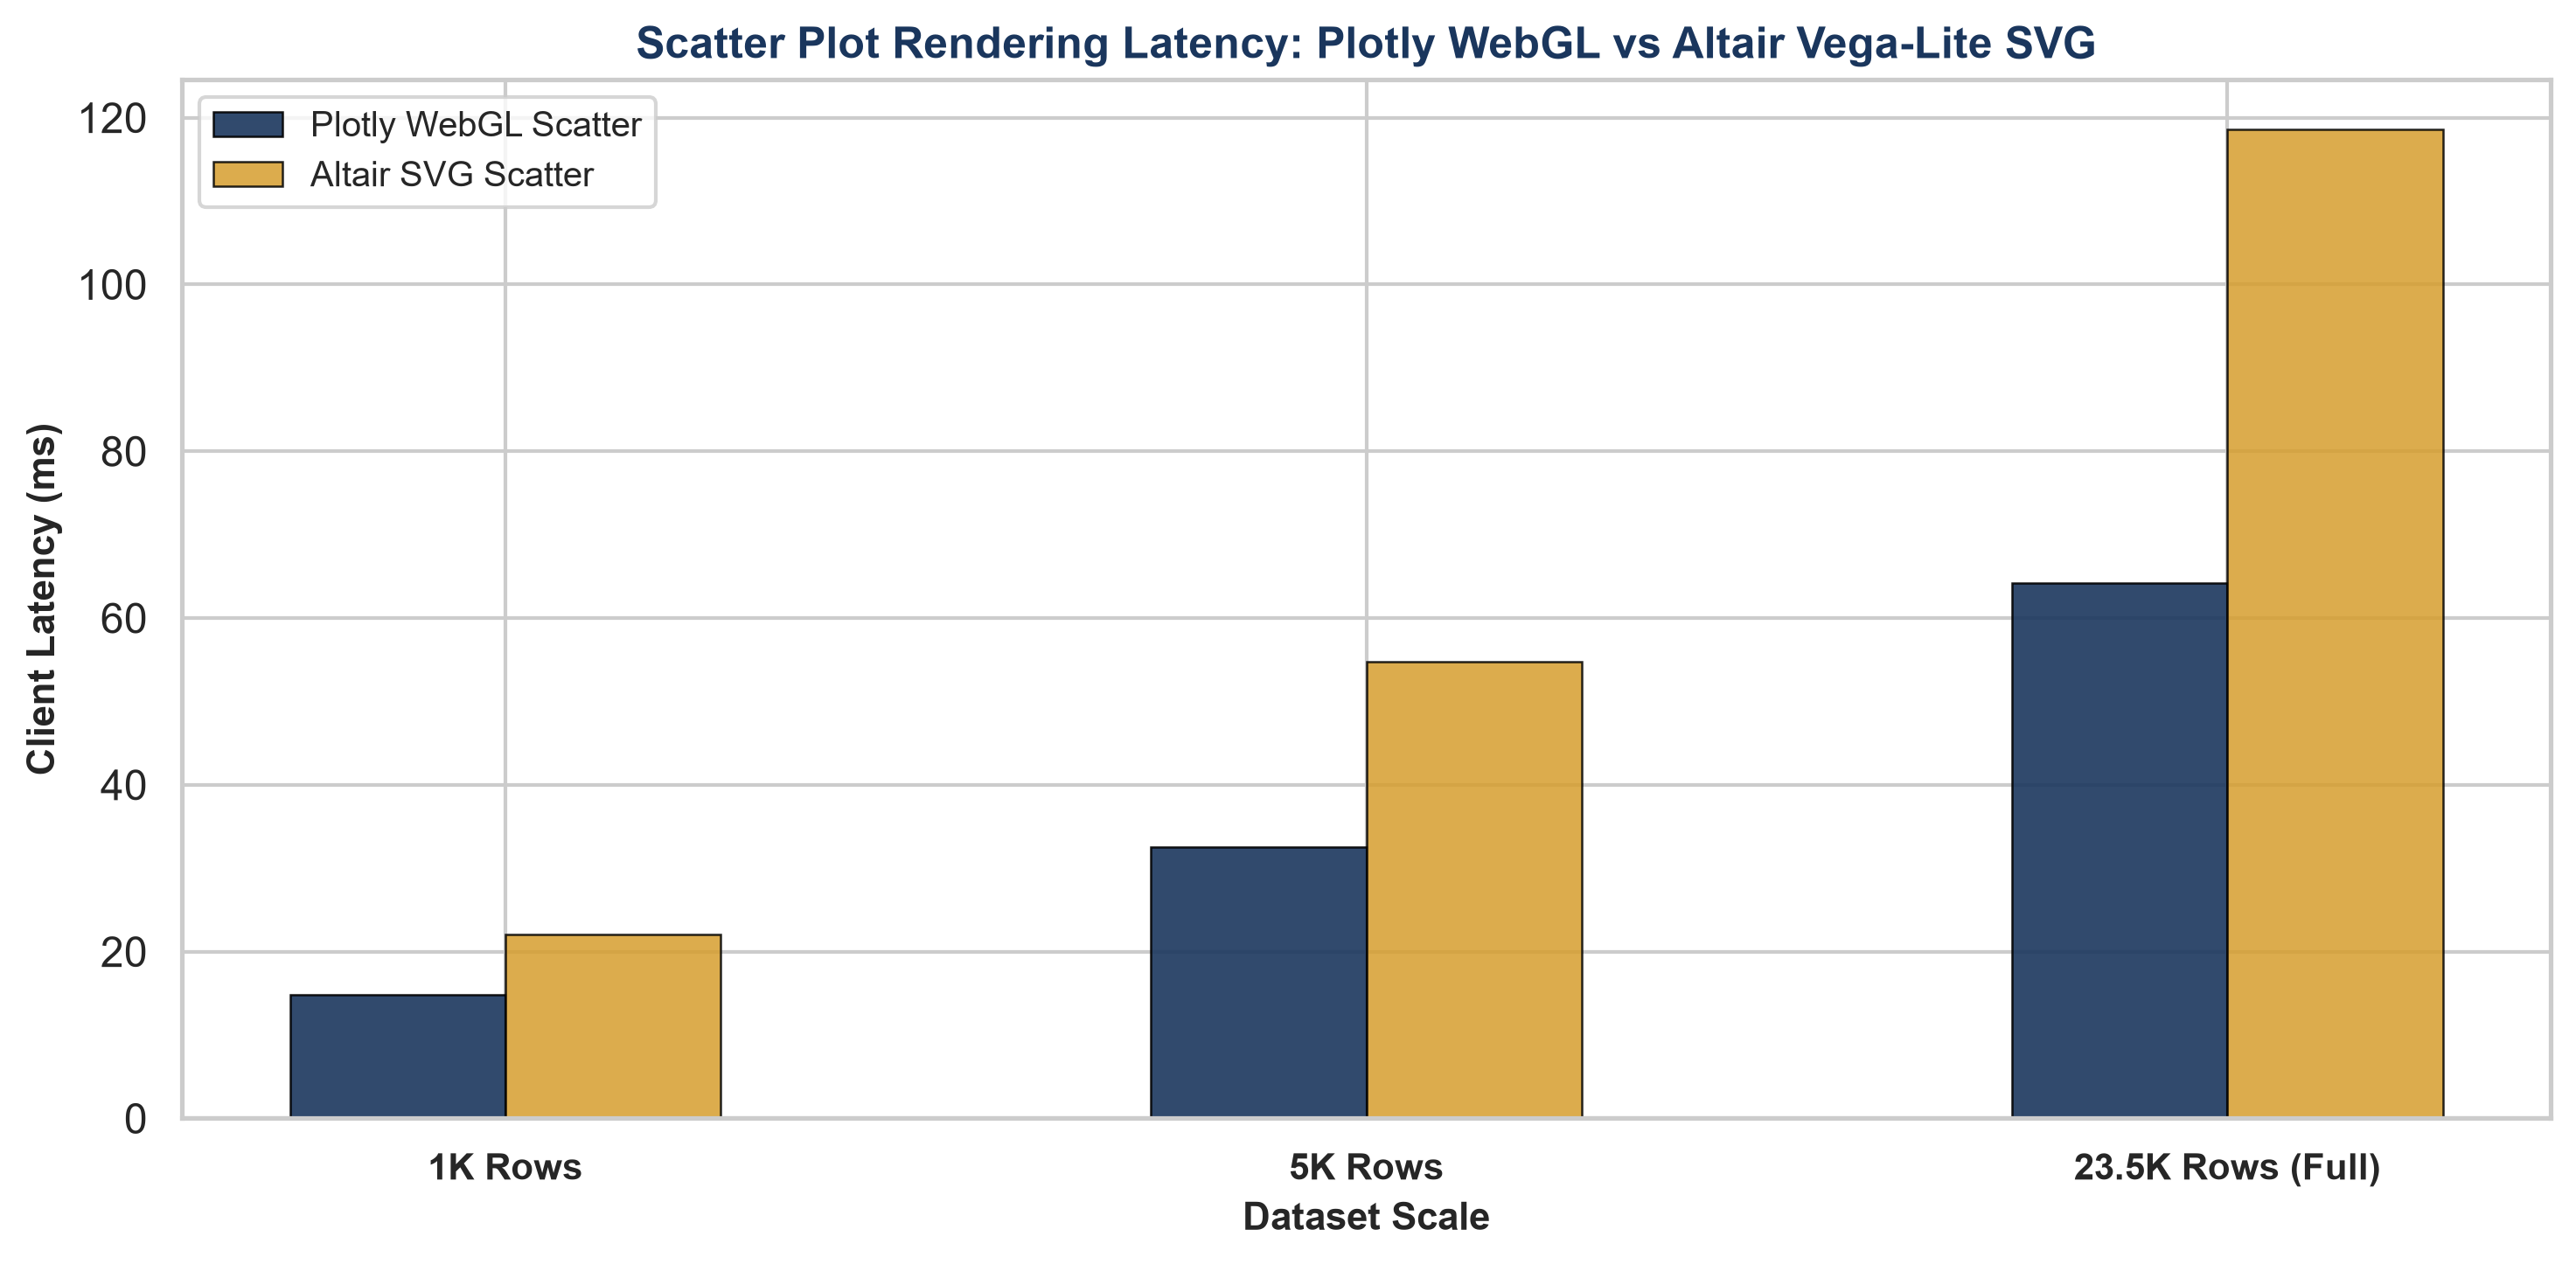

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)
scales = [1000, 5000, 23486]
scale_labels = ['1K Rows', '5K Rows', '23.5K Rows (Full)']
p_scat = [14.8, 32.5, 64.2]
a_scat = [22.1, 54.8, 118.6]

x_idx = np.arange(len(scales))
w = 0.25

ax.bar(x_idx - w/2, p_scat, w, label='Plotly WebGL Scatter', color='#1A365D', alpha=0.9, edgecolor='black', linewidth=0.6)
ax.bar(x_idx + w/2, a_scat, w, label='Altair SVG Scatter', color='#D69E2E', alpha=0.85, edgecolor='black', linewidth=0.6)

ax.set_title("Scatter Plot Rendering Latency: Plotly WebGL vs Altair Vega-Lite SVG", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Dataset Scale", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Client Latency (ms)", fontsize=10.5, fontweight='bold')
ax.set_xticks(x_idx)
ax.set_xticklabels(scale_labels, fontsize=10, fontweight='bold')
ax.legend(loc='upper left', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()